# Home Loan Data Analysis: predicting loan default with deep learning

**Goal:** build a deep learning model that predicts whether a loan applicant will have trouble repaying, using historical applications.

The data is highly imbalanced (only about 8% of applicants default) and has 122 columns, many with missing values. The notebook follows the 8 steps of the course brief:

1. Load the dataset
2. Check for null values
3. Print the percentage of defaulters and payers in `TARGET`
4. Balance the dataset
5. Plot the imbalanced and balanced data
6. Encode the columns the model needs
7. Calculate sensitivity
8. Calculate the area under the ROC curve (ROC-AUC)

**How to run:** keep `loan_data.csv` (and optionally `Data_Dictionary.csv`) in the same folder as this notebook, then choose **Run > Run All Cells**. It takes about 2 to 4 minutes on a laptop.

## Setup: import the libraries

- **pandas / numpy**: load and prepare the table of applications
- **matplotlib / seaborn**: charts
- **scikit-learn**: splitting, scaling and evaluation metrics
- **imbalanced-learn**: undersampling or SMOTE to balance the classes
- **TensorFlow / Keras**: the deep learning model

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow's start-up messages

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

import tensorflow as tf
import keras
from keras import layers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)   # makes results repeatable (Python, NumPy and TensorFlow)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 1: Load the dataset

In [2]:
df = pd.read_csv("loan_data.csv", low_memory=False)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


The data dictionary explains every column. A quick way to look one up:

In [3]:
if os.path.exists("Data_Dictionary.csv"):
    dictionary = pd.read_csv("Data_Dictionary.csv", encoding="latin-1")
    print(dictionary.loc[dictionary["Variable Name"].isin(["TARGET", "EXT_SOURCE_2", "DAYS_EMPLOYED"]),
                         ["Variable Name", "Description"]].to_string(index=False))

Variable Name                                         Description
       TARGET  Whether the loan was repaid (1 for yes, 0 for no).
DAYS_EMPLOYED How long the applicant has been employed (in days).


**Note on TARGET:** the course data dictionary says 1 means "repaid", but this is the standard Home Credit dataset, where **1 means the client had payment difficulties (default)** and 0 means they paid. The 8% share of 1s confirms it, so this notebook treats **1 = defaulter, 0 = payer**.

## Step 2: Check for null values

Columns with missing values: 67 of 122
Columns more than 40% empty: 49


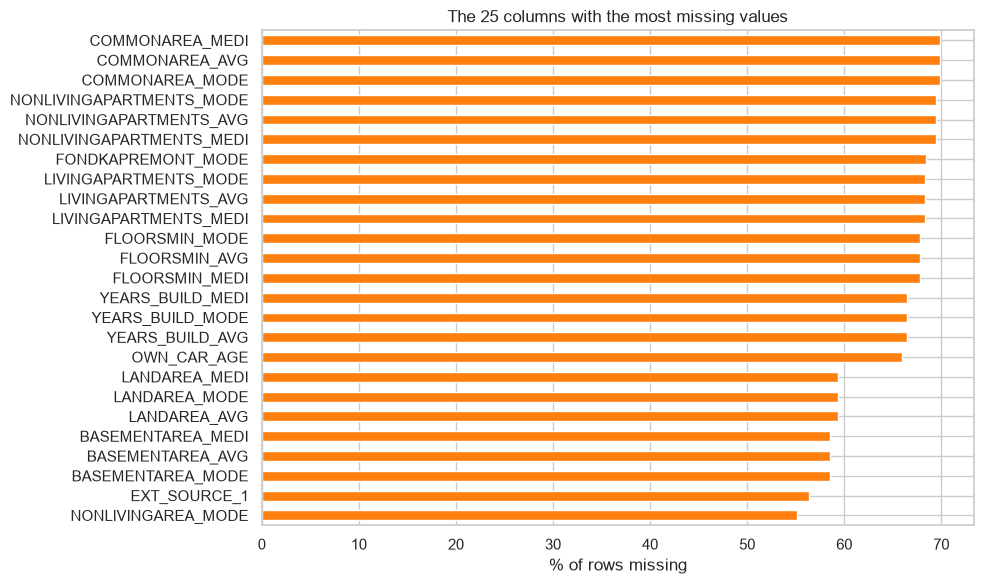

In [4]:
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print(f"Columns with missing values: {(missing_pct > 0).sum()} of {df.shape[1]}")
print(f"Columns more than 40% empty: {(missing_pct > 40).sum()}")

plt.figure(figsize=(10, 6))
missing_pct.head(25).sort_values().plot.barh(color="tab:orange")
plt.xlabel("% of rows missing")
plt.title("The 25 columns with the most missing values")
plt.tight_layout()
plt.show()

**How we treat missing and wrong values:**

- Columns more than 40% empty are dropped: they are mostly building details (names ending in `_AVG`, `_MODE`, `_MEDI`) and are too sparse to trust.
- `DAYS_EMPLOYED` uses 365243 as a placeholder (it would mean 1,000 years of work), so we turn it into a missing value and add a flag column.
- `CODE_GENDER` has 4 rows marked `XNA`; they get the most common value.
- Missing text values become `"Unknown"`. Missing numbers are filled with the **median of the training set** later, after the split, so the test set never influences training.
- `SK_ID_CURR` is just an ID, so it isn't used as a feature.

In [5]:
MISSING_THRESHOLD = 40   # drop columns with more than 40% missing values

cols_to_drop = missing_pct[missing_pct > MISSING_THRESHOLD].index.tolist()
data = df.drop(columns=cols_to_drop + ["SK_ID_CURR"])

data["DAYS_EMPLOYED_ANOMALY"] = (data["DAYS_EMPLOYED"] == 365243).astype(int)
data["DAYS_EMPLOYED"] = data["DAYS_EMPLOYED"].replace(365243, np.nan)
data["CODE_GENDER"] = data["CODE_GENDER"].replace("XNA", data["CODE_GENDER"].mode()[0])

text_cols = data.select_dtypes(exclude="number").columns
data[text_cols] = data[text_cols].fillna("Unknown")

print("Dropped columns:", len(cols_to_drop))
print("Remaining shape:", data.shape)

Dropped columns: 49
Remaining shape: (307511, 73)


## Step 3: Percentage of defaulters and payers

In [6]:
target_pct = data["TARGET"].value_counts(normalize=True).sort_index() * 100
print(f"Payers     (TARGET = 0): {target_pct[0]:.2f}%")
print(f"Defaulters (TARGET = 1): {target_pct[1]:.2f}%")

Payers     (TARGET = 0): 91.93%
Defaulters (TARGET = 1): 8.07%


Only about 8% of applicants default. A model that predicts "pays" for everyone would be about 92% accurate and completely useless, which is why we balance the data and judge the model on **sensitivity** and **ROC-AUC** rather than accuracy.

## Step 6: Encode the columns the model needs

Encoding comes before balancing in practice, because SMOTE and the neural network only work with numbers.

- Text columns with exactly two values (such as `FLAG_OWN_CAR`: Y/N) become a single 0/1 column.
- Text columns with more values (such as `NAME_INCOME_TYPE` or `ORGANIZATION_TYPE`) are **one-hot encoded**: one 0/1 column per category.

In [7]:
binary_cols = [c for c in text_cols if data[c].nunique() == 2]
multi_cols = [c for c in text_cols if data[c].nunique() > 2]

for col in binary_cols:
    first_value = sorted(data[col].unique())[0]
    data[col] = (data[col] != first_value).astype(int)

data = pd.get_dummies(data, columns=multi_cols, dtype=int)

print("Two-value columns encoded as 0/1:", binary_cols)
print("Columns one-hot encoded:", len(multi_cols))
print("Final table shape:", data.shape)

Two-value columns encoded as 0/1: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
Columns one-hot encoded: 8
Final table shape: (307511, 182)


### Split, fill and scale

- **Stratified 80:20 split:** the test set keeps the real 92:8 mix and is never used for training.
- Missing numbers are filled with the training-set median.
- **Scaling:** neural networks learn best when every column is on a similar scale, so `StandardScaler` (fitted on training data only) gives each column mean 0 and standard deviation 1.
- A slice of the training data is kept aside as a **validation set** to watch the model during training.

In [8]:
X = data.drop(columns="TARGET")
y = data["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_scaled, y_train.values, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

print("Model training rows:", X_fit.shape, "  Validation rows:", X_val.shape, "  Test rows:", X_test_scaled.shape)
print(f"Defaulters in each set: train {y_fit.mean():.1%}, validation {y_val.mean():.1%}, test {y_test.mean():.1%}")

Model training rows: (209106, 181)   Validation rows: (36902, 181)   Test rows: (61503, 181)
Defaulters in each set: train 8.1%, validation 8.1%, test 8.1%


## Step 4: Balance the dataset

Only the training rows are balanced; validation and test data keep the real mix, so the scores stay honest. Two options:

- **`"undersample"` (default):** keep every defaulter and an equal random sample of payers. Fast and light on memory, ideal for a laptop.
- **`"smote"`:** keep everyone and create synthetic defaulters. Uses all the data but needs more memory and a longer training time.

In [9]:
BALANCE_METHOD = "undersample"   # or "smote"

if BALANCE_METHOD == "smote":
    balancer = SMOTE(random_state=RANDOM_STATE)
else:
    balancer = RandomUnderSampler(random_state=RANDOM_STATE)

X_bal, y_bal = balancer.fit_resample(X_fit, y_fit)

def class_counts(labels):
    values, counts = np.unique(labels, return_counts=True)
    return {int(v): int(c) for v, c in zip(values, counts)}

print("Before balancing:", class_counts(y_fit))
print("After balancing: ", class_counts(y_bal))

Before balancing: {0: 192225, 1: 16881}
After balancing:  {0: 16881, 1: 16881}


## Step 5: Plot the imbalanced and balanced data

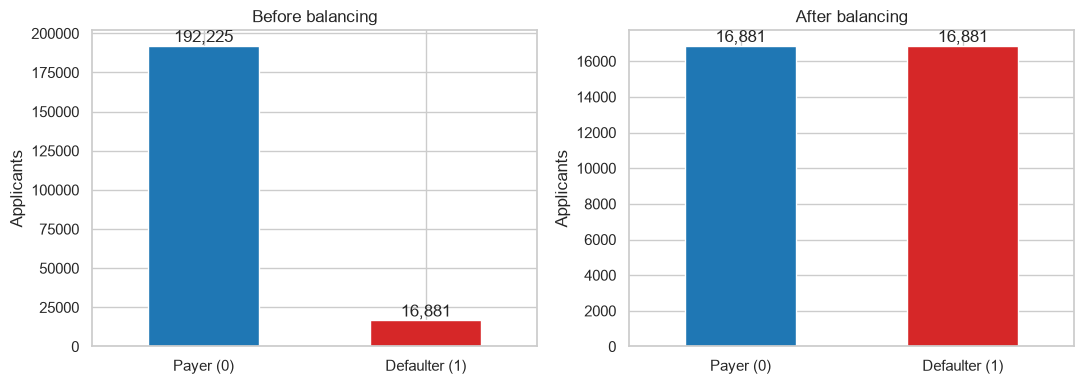

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labels, title in zip(axes, [y_fit, y_bal], ["Before balancing", "After balancing"]):
    counts = pd.Series(labels).value_counts().sort_index()
    counts.index = ["Payer (0)", "Defaulter (1)"]
    counts.plot.bar(ax=ax, color=["tab:blue", "tab:red"], rot=0, title=title)
    ax.set_ylabel("Applicants")
    for i, v in enumerate(counts):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Build and train the deep learning model

A **feed-forward neural network** built with Keras:

- Three hidden layers of 128, 64 and 32 neurons with **ReLU** activation learn the patterns.
- **Batch normalisation** keeps training stable, and **dropout** (randomly switching off 30% of neurons while training) prevents memorising.
- One output neuron with a **sigmoid** activation gives the probability of default, between 0 and 1.
- **Adam** optimiser, **binary cross-entropy** loss, and recall and AUC tracked as metrics.
- **Early stopping** ends training when validation AUC stops improving and keeps the best version.

In [11]:
model = keras.Sequential([
    keras.Input(shape=(X_bal.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=[keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        23,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,433 (134.50 KB)

 Trainable params: 34,049 (133.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [12]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                           restore_best_weights=True)

history = model.fit(X_bal, y_bal.astype("float32"),
                    validation_data=(X_val, y_val.astype("float32")),
                    epochs=50, batch_size=256,
                    callbacks=[early_stop], verbose=2)

Epoch 1/50
132/132 - 2s - 17ms/step - auc: 0.6189 - loss: 0.7120 - recall: 0.6473 - val_auc: 0.6939 - val_loss: 0.5851 - val_recall: 0.5237
Epoch 2/50
132/132 - 0s - 2ms/step - auc: 0.6924 - loss: 0.6409 - recall: 0.6385 - val_auc: 0.7190 - val_loss: 0.5843 - val_recall: 0.6052
Epoch 3/50
132/132 - 0s - 2ms/step - auc: 0.7140 - loss: 0.6234 - recall: 0.6514 - val_auc: 0.7225 - val_loss: 0.5833 - val_recall: 0.6247
Epoch 4/50
132/132 - 0s - 2ms/step - auc: 0.7276 - loss: 0.6114 - recall: 0.6657 - val_auc: 0.7257 - val_loss: 0.5807 - val_recall: 0.6391
Epoch 5/50
132/132 - 0s - 2ms/step - auc: 0.7325 - loss: 0.6077 - recall: 0.6727 - val_auc: 0.7271 - val_loss: 0.5862 - val_recall: 0.6563
Epoch 6/50
132/132 - 0s - 2ms/step - auc: 0.7378 - loss: 0.6028 - recall: 0.6770 - val_auc: 0.7279 - val_loss: 0.5828 - val_recall: 0.6469
Epoch 7/50
132/132 - 0s - 2ms/step - auc: 0.7428 - loss: 0.5988 - recall: 0.6808 - val_auc: 0.7276 - val_loss: 0.5783 - val_recall: 0.6445
Epoch 8/50
132/132 - 0s - 

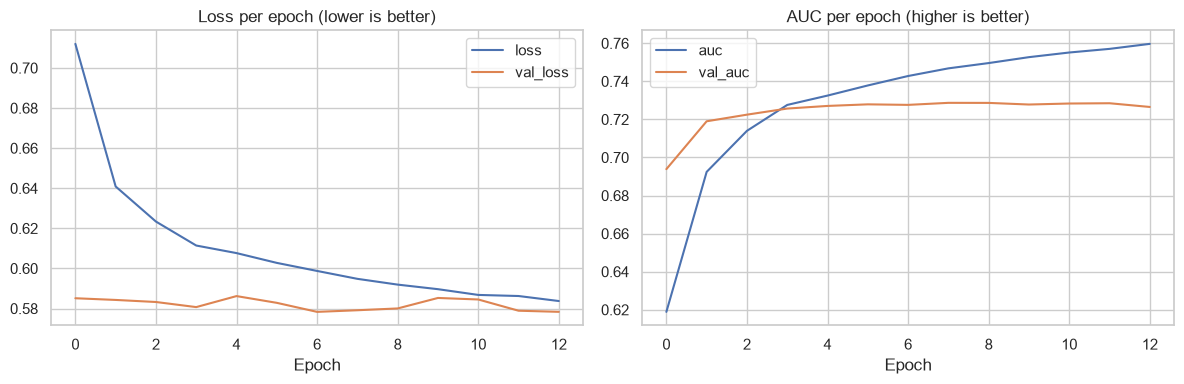

In [13]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss per epoch (lower is better)")
hist[["auc", "val_auc"]].plot(ax=axes[1], title="AUC per epoch (higher is better)")
for ax in axes:
    ax.set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## Step 7: Calculate sensitivity

**Sensitivity** (also called recall) answers: of all the applicants who really defaulted, how many did the model catch?

Sensitivity = true positives ÷ (true positives + false negatives)

The model outputs a probability; an applicant is flagged as a likely defaulter when it is 0.5 or higher. We measure on the untouched test set.

Sensitivity (defaulters caught): 0.637
Specificity (payers correctly cleared): 0.708
Caught 3,164 of 4,965 defaulters; 16,500 payers were flagged by mistake.

               precision    recall  f1-score   support

    Payer (0)      0.957     0.708     0.814     56538
Defaulter (1)      0.161     0.637     0.257      4965

     accuracy                          0.702     61503
    macro avg      0.559     0.673     0.535     61503
 weighted avg      0.893     0.702     0.769     61503



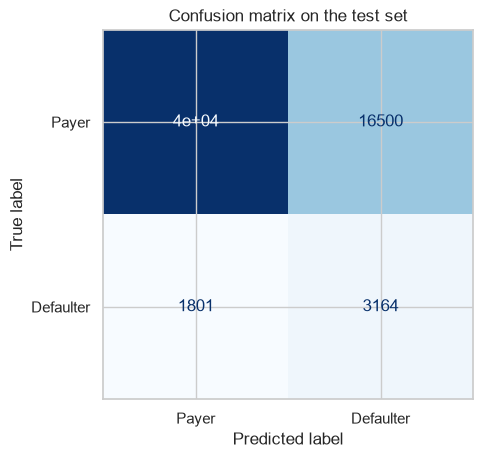

In [14]:
THRESHOLD = 0.5

y_prob = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Sensitivity (defaulters caught): {sensitivity:.3f}")
print(f"Specificity (payers correctly cleared): {specificity:.3f}")
print(f"Caught {tp:,} of {tp + fn:,} defaulters; {fp:,} payers were flagged by mistake.\n")
print(classification_report(y_test, y_pred, target_names=["Payer (0)", "Defaulter (1)"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Payer", "Defaulter"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set")
plt.show()

**Why sensitivity matters here:** missing a defaulter (a false negative) means a loss on the loan, while wrongly flagging a payer (a false positive) usually just means an extra review. Lowering `THRESHOLD` catches more defaulters at the cost of more reviews; raising it does the opposite.

## Step 8: Area under the ROC curve

The ROC curve shows the trade-off between catching defaulters (true positive rate) and flagging payers (false positive rate) at every possible threshold. **AUC** sums it up: 0.5 is a coin flip and 1.0 is perfect. It measures how well the model ranks risky applicants above safe ones.

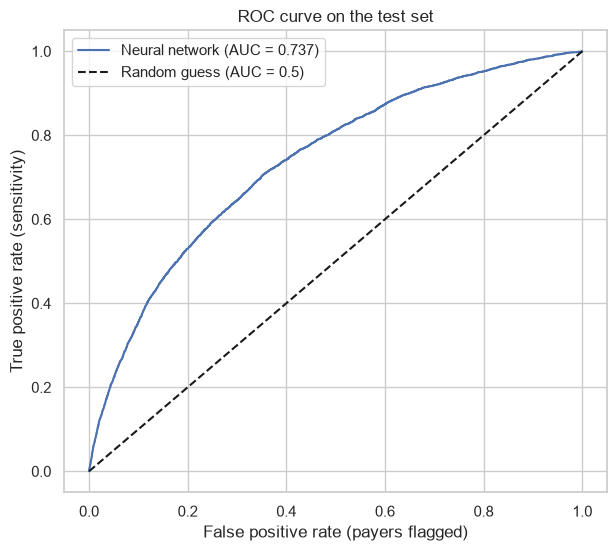

ROC-AUC on the test set: 0.737


In [15]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Neural network (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate (payers flagged)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curve on the test set")
plt.legend()
plt.show()

print(f"ROC-AUC on the test set: {auc:.3f}")

## Conclusion

- The data was cleaned (sparse columns dropped, placeholder values fixed, gaps filled), encoded into numbers and scaled.
- Only about 8% of applicants default, so the training data was balanced while the test set kept the real mix.
- A Keras neural network with dropout, batch normalisation and early stopping predicts the chance of default.
- It is judged on **sensitivity** (how many real defaulters it catches) and **ROC-AUC** (how well it ranks risky above safe), not accuracy.
- Ideas to improve it: try `BALANCE_METHOD = "smote"`, tune the threshold, or tune the layers and dropout with Keras Tuner.